# Workshop 3 - Gold outputs

Team 9 - Multi-Hazard Weather Impact Monitoring.

These are real outputs of the local PySpark/Airflow Gold pipeline. We inspect
the two saved datasets with Pandas. This notebook does not run Spark, query NWS
or access PostgreSQL. The first quality notebook motivates the methods; the
Gold contract documents the fields, estimators and dashboard questions.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "workshop_3/evidence/gold_samples.json").exists())
register = json.loads((root / "workshop_3/evidence/gold_samples.json").read_text())
tables = {}
for name, item in register["outputs"].items():
    path = root / item["path"]
    assert hashlib.sha256(path.read_bytes()).hexdigest().upper() == item["sha256"]
    tables[name] = pd.read_parquet(path)
    assert len(tables[name]) == item["rows"]
governance, storytelling = tables["governance"], tables["storytelling"]
print("Actual Airflow run:", register["dag_run_id"])
display(governance.head())
display(storytelling.head())

Actual Airflow run: w3_gold_20261121T144317


,source,station,population,period,variable,unit,metric,value,numerator,denominator,method,status,batch_id
0,ghcn_daily,NaN,unique_source_records,2021-01,NaN,NaN,monthly_records,93.0,NaN,NaN,exact_count,available,w3_gold_20261121T144317
1,ghcn_daily,NaN,unique_source_records,2021-02,NaN,NaN,monthly_records,84.0,NaN,NaN,exact_count,available,w3_gold_20261121T144317
2,ghcn_daily,NaN,unique_source_records,2021-03,NaN,NaN,monthly_records,93.0,NaN,NaN,exact_count,available,w3_gold_20261121T144317
3,ghcn_daily,NaN,unique_source_records,2021-04,NaN,NaN,monthly_records,90.0,NaN,NaN,exact_count,available,w3_gold_20261121T144317
4,ghcn_daily,NaN,unique_source_records,2021-05,NaN,NaN,monthly_records,93.0,NaN,NaN,exact_count,available,w3_gold_20261121T144317


,source,station,geographic_scope,period,event_type,severity_unit,record_count,measured_count,mean_value,min_value,max_value,observed_dates,missing_point_count,precipitation_total_mm,batch_id,analysis_type
0,ghcn_daily,USW00013967,station_only,2021-01,PRCP,mm,31,31,1.325806,0.0,15.2,31,0,41.1,w3_gold_20261121T144317,descriptive_not_forecast
1,ghcn_daily,USW00013967,station_only,2021-01,TMAX,degC,31,31,9.183871,1.1,19.4,31,0,NaN,w3_gold_20261121T144317,descriptive_not_forecast
2,ghcn_daily,USW00013967,station_only,2021-01,TMIN,degC,31,31,-1.190323,-7.1,5.0,31,0,NaN,w3_gold_20261121T144317,descriptive_not_forecast
3,ghcn_daily,USW00013967,station_only,2021-02,PRCP,mm,28,28,0.625000,0.0,7.4,28,0,17.5,w3_gold_20261121T144317,descriptive_not_forecast
4,ghcn_daily,USW00013967,station_only,2021-02,TMAX,degC,28,28,4.696429,-15.5,22.2,28,0,NaN,w3_gold_20261121T144317,descriptive_not_forecast


## 1. Schema and keys

Governance is a long metric table with availability and method fields. Storytelling
is monthly per-source/type/unit and station where applicable. Null station values
for statewide event records are intentional; county allocation is not implemented.

In [2]:
governance.info()
storytelling.info()
assert not governance.duplicated(["source", "station", "population", "period", "variable", "unit", "metric"]).any()
assert not storytelling.duplicated(["source", "station", "period", "event_type", "severity_unit"]).any()
display(storytelling.groupby("source")["record_count"].sum().to_frame("unique_source_records"))

<class 'pandas.DataFrame'>
RangeIndex: 625 entries, 0 to 624
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   source       625 non-null    str    
 1   station      481 non-null    str    
 2   population   625 non-null    str    
 3   period       625 non-null    str    
 4   variable     494 non-null    str    
 5   unit         480 non-null    str    
 6   metric       625 non-null    str    
 7   value        615 non-null    float64
 8   numerator    131 non-null    float64
 9   denominator  141 non-null    float64
 10  method       625 non-null    str    
 11  status       625 non-null    str    
 12  batch_id     625 non-null    str    
dtypes: float64(3), str(10)
memory usage: 140.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   source              

,unique_source_records
source,
ghcn_daily,5478
noaa_storm_events,13561


## 2. Governance: quality and snapshot volume

Repeated exports are not additional weather events. Null fractions describe a
specific source/field; some nulls express a different time grain, not missing
observations. Structural compliance is not a certification of all provider QC.

In [3]:
metrics = ["snapshot_rows", "unique_records", "repeated_snapshot_fraction", "schema_compliance_fraction"]
display(governance[governance["metric"].isin(metrics)][["source", "metric", "value", "method"]])
nulls = governance[governance["metric"].eq("null_fraction")]
display(nulls.pivot(index="variable", columns="source", values="value"))
review = governance[governance["population"].isin(["all_days", "positive_reported_precipitation"]) &
                    governance["metric"].isin(["sample_skewness", "sample_excess_kurtosis", "iqr_review_fraction", "zscore_review_fraction"])]
display(review[["station", "variable", "population", "metric", "value", "numerator", "denominator", "status"]])
zero_iqr = review[review["variable"].eq("PRCP") & review["population"].eq("all_days") & review["metric"].eq("iqr_review_fraction")]
assert zero_iqr["value"].isna().all()
assert zero_iqr["status"].eq("unavailable_zero_or_missing_scale").all()

,source,metric,value,method
60,ghcn_daily,snapshot_rows,7668.000000,includes_replayed_exports
61,ghcn_daily,unique_records,5478.000000,latest_successful_local_run_per_source_key
62,ghcn_daily,repeated_snapshot_fraction,0.285603,repeated_export_rows_not_independent_duplicate...
64,ghcn_daily,schema_compliance_fraction,1.000000,all_18_silver_types_and_required_identity_time...
613,noaa_storm_events,snapshot_rows,14885.000000,includes_replayed_exports
614,noaa_storm_events,unique_records,13561.000000,latest_successful_local_run_per_source_key
615,noaa_storm_events,repeated_snapshot_fraction,0.088949,repeated_export_rows_not_independent_duplicate...
617,noaa_storm_events,schema_compliance_fraction,1.000000,all_18_silver_types_and_required_identity_time...


source,ghcn_daily,noaa_storm_events
variable,,
latitude,0.0,0.522380
longitude,0.0,0.522380
observed_at_utc,1.0,0.000000
observed_date,0.0,1.000000
quality_attributes,0.0,1.000000
severity_unit,0.0,0.562127
severity_value,0.0,0.562127


,station,variable,population,metric,value,numerator,denominator,status
80,USW00013967,PRCP,all_days,sample_skewness,7.296155,NaN,NaN,available
81,USW00013967,PRCP,all_days,sample_excess_kurtosis,89.637273,NaN,NaN,available
82,USW00013967,PRCP,all_days,iqr_review_fraction,NaN,NaN,1826.0,unavailable_zero_or_missing_scale
83,USW00013967,PRCP,all_days,zscore_review_fraction,0.025192,46.0,1826.0,available
92,USW00013967,TMAX,all_days,sample_skewness,-0.617717,NaN,NaN,available
93,USW00013967,TMAX,all_days,sample_excess_kurtosis,-0.058923,NaN,NaN,available
94,USW00013967,TMAX,all_days,iqr_review_fraction,0.007667,14.0,1826.0,available
95,USW00013967,TMAX,all_days,zscore_review_fraction,0.004929,9.0,1826.0,available
104,USW00013967,TMIN,all_days,sample_skewness,-0.420144,NaN,NaN,available
105,USW00013967,TMIN,all_days,sample_excess_kurtosis,-0.713884,NaN,NaN,available


## 3. Storytelling: what was recorded?

Plot reported Storm Events records by month, then station temperature and rain
separately. One station is not statewide measured weather. Monthly means of
daily TMAX/TMIN are not monthly absolute maxima/minima. Rain totals are meaningful;
sums of temperatures and storm magnitudes are deliberately absent.

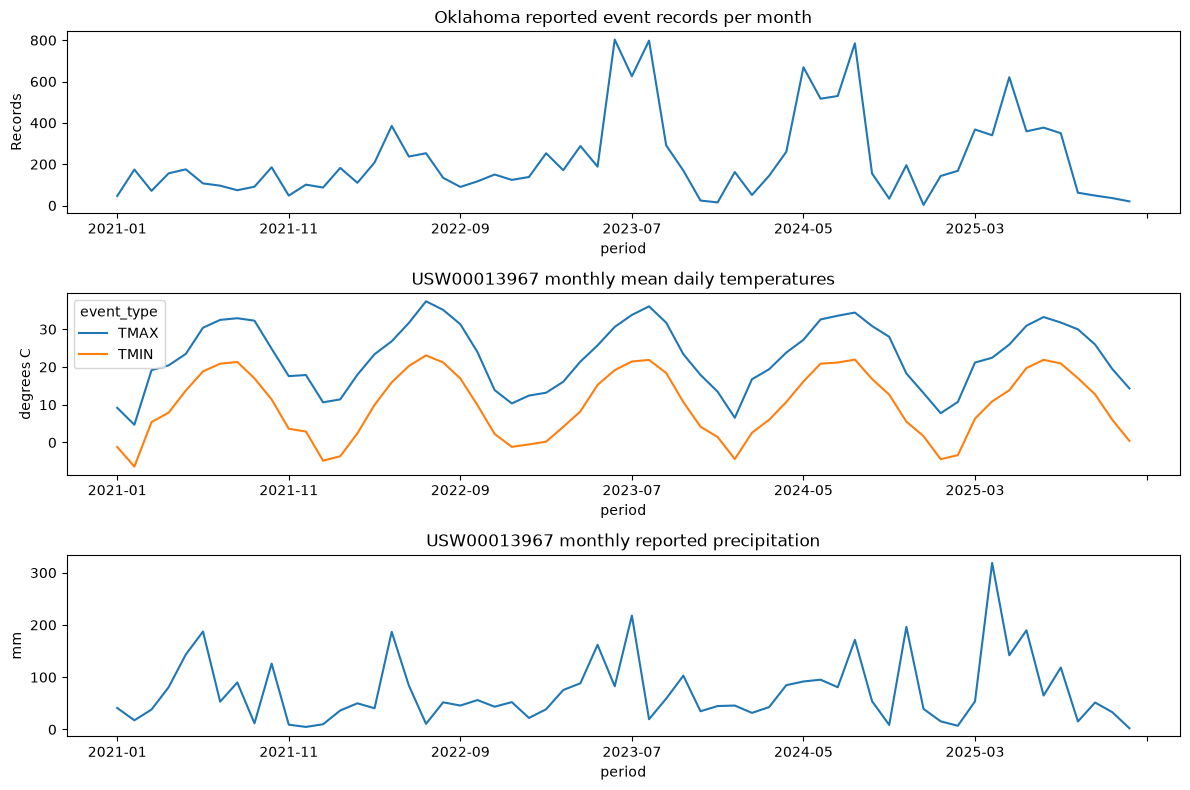

,station,period,event_type,record_count,measured_count,mean_value,precipitation_total_mm
0,USW00013967,2021-01,PRCP,31,31,1.325806,41.1
1,USW00013967,2021-01,TMAX,31,31,9.183871,NaN
2,USW00013967,2021-01,TMIN,31,31,-1.190323,NaN
3,USW00013967,2021-02,PRCP,28,28,0.625000,17.5
4,USW00013967,2021-02,TMAX,28,28,4.696429,NaN
5,USW00013967,2021-02,TMIN,28,28,-6.375000,NaN
6,USW00013967,2021-03,PRCP,31,31,1.229032,38.1
7,USW00013967,2021-03,TMAX,31,31,19.145161,NaN
8,USW00013967,2021-03,TMIN,31,31,5.406452,NaN


In [4]:
events = storytelling[storytelling["source"].eq("noaa_storm_events")]
daily = storytelling[storytelling["source"].eq("ghcn_daily")]
assert storytelling.loc[~storytelling["event_type"].eq("PRCP"), "precipitation_total_mm"].isna().all()
event_counts = events.groupby("period")["record_count"].sum()
temperature = daily[daily["event_type"].isin(["TMAX", "TMIN"])].pivot(index="period", columns="event_type", values="mean_value")
rain = daily[daily["event_type"].eq("PRCP")].set_index("period")["precipitation_total_mm"]
fig, axes = plt.subplots(3, 1, figsize=(12, 8))
event_counts.plot(ax=axes[0], title="Oklahoma reported event records per month")
temperature.plot(ax=axes[1], title="USW00013967 monthly mean daily temperatures")
rain.plot(ax=axes[2], title="USW00013967 monthly reported precipitation")
axes[0].set_ylabel("Records")
axes[1].set_ylabel("degrees C")
axes[2].set_ylabel("mm")
plt.tight_layout()
plt.show()
display(daily[["station", "period", "event_type", "record_count", "measured_count", "mean_value", "precipitation_total_mm"]].head(9))

## 4. Reconciliation and dashboard handoff

The separate Pandas reconciliation checks the same Silver input hashes,
deduplication, source totals, sample shape estimators and station/month aggregates.
These descriptive/diagnostic inputs are ready to inform dashboard design;
they do not implement CHI, forecasting, causality or a completed Dash application.

In [5]:
audit = json.loads((root / "workshop_3/evidence/gold_reconciliation.json").read_text())
assert audit["output_hashes_verified"] and audit["unique_gold_keys"]
assert audit["source_record_totals_reconciled"] and audit["zero_iqr_not_fabricated"]
display(pd.Series(audit))
print("Gold previews completed without source or database calls.")

manifest                                  data/gold/20261121_144319_caeba6938516/manifes...
manifest_sha256                           A413FAB0E5CDA49CBD6B814915261D830CDE2D886C25F0...
counts                                    {'snapshot_rows': 22553, 'unique_business_reco...
gold_rows                                          {'governance': 625, 'storytelling': 607}
matching_pandas_shape_statistics                                                         40
matching_station_month_groups                                                           180
matching_storm_month_type_unit_groups                                                   427
output_hashes_verified                                                                 True
unique_gold_keys                                                                       True
source_record_totals_reconciled                                                        True
no_temperature_or_event_magnitude_sums                                          

Gold previews completed without source or database calls.
